# Geometry + Colorimetry Fusion: Pre / Per / Post-Exercise Classification

This notebook combines the two approaches previously tested:
- **Colorimetry** (`colorimetry` notebook): 7 best features (selected based on Random Forest feature importance).
- **Facial Geometry** (`geometric-features` notebook): 3 best features (mouth-related features).



## 1 - Library

In [64]:
import urllib.request
from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

# ---------- Parameters ----------
DOSSIER = Path("../dataset_computervision_LECSIN/dataset_squat")   # Adapt if needed
GROUPES = ["pre", "per", "post"]
SEED = 42
ROI_RATIO = 0.6            # Central face region used for colorimetry
Path("figures").mkdir(exist_ok=True)

# ---------- Selected features (top features from both notebooks) ----------
TOP_COLOR = ["moyenne_srgb_R","contraste_rms", "face_y"]   # Top 3 colorimetry features
TOP_GEO = ["mouth_opening_ratio", "mouth_corner_angle_deg", "mouth_edge_density"]   # Top 3 geometry features
TOP_FUSION = TOP_COLOR + TOP_GEO

SOURCE = {**{f: "colorimetry" for f in TOP_COLOR}, **{f: "geometry" for f in TOP_GEO}}

## 2 - Features Function

### 2.1 Face Detection (Viola-Jones)

In [65]:
_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if _CASCADE.empty():
    raise RuntimeError("Cascade not loaded: check your OpenCV installation")


def detect_face(img, scale_factor=1.1, min_neighbors=5, min_size=(60, 60)):
    """Input: BGR image. Output: bbox (x, y, w, h) of the largest face, or None."""
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    visages = _CASCADE.detectMultiScale(gris, scaleFactor=scale_factor,
                                        minNeighbors=min_neighbors, minSize=min_size)
    if len(visages) == 0:
        return None
    x, y, w, h = max(visages, key=lambda b: b[2] * b[3])
    return int(x), int(y), int(w), int(h)


def reframe(img, bbox, roi_ratio=1.0):
    """Crop the bounding box (roi_ratio=1.0: full face; 0.6: face center)."""
    x, y, w, h = bbox
    dx, dy = int(w * (1 - roi_ratio) / 2), int(h * (1 - roi_ratio) / 2)
    return img[y + dy : y + h - dy, x + dx : x + w - dx]

### 2.2 Colorimetric features

In [66]:
CANAUX = ("B", "G", "R")   # OpenCV channel order

_niveaux = np.arange(256, dtype=np.float32) / 255.0
_LUT_LIN_U8 = np.where(_niveaux <= 0.04045, _niveaux / 12.92,
                       ((_niveaux + 0.055) / 1.055) ** 2.4).astype(np.float32)

# Ligne Y et somme des lignes X, Y, Z de la matrice sRGB -> XYZ (seul y est nécessaire)
_Y_ROW = np.array([0.2126729, 0.7151522, 0.0721750])
_SUM_ROW = np.array([0.4124564 + 0.2126729 + 0.0193339,
                     0.3575761 + 0.7151522 + 0.1191920,
                     0.1804375 + 0.0721750 + 0.9503041])


def _valeur_max(img):
    return float(np.iinfo(img.dtype).max) if np.issubdtype(img.dtype, np.integer) else 1.0


def normaliser(img):
    """BGR image -> float32 in [0, 1] (sRGB values)."""
    return img.astype(np.float32) * np.float32(1.0 / _valeur_max(img))


def srgb_vers_lineaire(img_bgr):
    """BGR image -> linear light float32 in [0, 1]."""
    if img_bgr.dtype == np.uint8:
        return cv2.LUT(img_bgr, _LUT_LIN_U8)
    c = normaliser(img_bgr)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4).astype(np.float32)


def colorimetry(img, bbox, roi_ratio=ROI_RATIO):
    """Input: BGR image + face bounding box. Output: the 3 top colorimetric features."""
    roi = reframe(img, bbox, roi_ratio)
    v_srgb = normaliser(roi)

    # moyenne_srgb_R : moyenne du canal rouge (sRGB, BGR -> index 2)
    moyenne_srgb_R = float(v_srgb[..., 2].mean(dtype=np.float64))

    # contraste_rms : écart-type de la luma sRGB
    luma = 0.0722 * v_srgb[..., 0] + 0.7152 * v_srgb[..., 1] + 0.2126 * v_srgb[..., 2]
    contraste_rms = float(luma.std(dtype=np.float64))

    # face_y : chromaticité CIE y du visage (RGB linéaire moyen)
    rgb_lin = srgb_vers_lineaire(roi).reshape(-1, 3).mean(axis=0, dtype=np.float64)[::-1]
    face_y = float((_Y_ROW @ rgb_lin) / (_SUM_ROW @ rgb_lin + 1e-12))

    return {"moyenne_srgb_R": moyenne_srgb_R,
            "contraste_rms": contraste_rms,
            "face_y": face_y}

### 2.3 Geometric features (MediaPipe FaceLandmarker + contours)

In [67]:
def remove_background(visage, iterations=1):
    """Replaces the background of the face crop with its median color (GrabCut)."""
    h, w = visage.shape[:2]
    masque = np.full((h, w), cv2.GC_PR_BGD, dtype=np.uint8)
    bord = max(2, int(min(h, w) * 0.04))
    masque[bord:-bord, bord:-bord] = cv2.GC_PR_FGD
    cv2.ellipse(masque, (w // 2, h // 2), (int(w * 0.42), int(h * 0.48)), 0, 0, 360, cv2.GC_FGD, -1)
    cv2.grabCut(visage, masque, None, np.zeros((1, 65)), np.zeros((1, 65)),
                iterations, cv2.GC_INIT_WITH_MASK)
    avant = np.isin(masque, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    avant = cv2.morphologyEx(cv2.morphologyEx(avant, cv2.MORPH_CLOSE, noyau), cv2.MORPH_OPEN, noyau)
    pixels_bord = np.concatenate((visage[:bord].reshape(-1, 3), visage[-bord:].reshape(-1, 3)))
    propre = np.broadcast_to(np.median(pixels_bord, axis=0).astype(np.uint8), visage.shape).copy()
    propre[avant > 0] = visage[avant > 0]
    return propre


_MODELE_LANDMARKS = Path("models/face_landmarker.task")
_URL_LANDMARKS = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                  "face_landmarker/float16/1/face_landmarker.task")
if not _MODELE_LANDMARKS.exists():
    _MODELE_LANDMARKS.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(_URL_LANDMARKS, _MODELE_LANDMARKS)
_LANDMARKER = mp.tasks.vision.FaceLandmarker.create_from_options(
    mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(_MODELE_LANDMARKS)),
        running_mode=mp.tasks.vision.RunningMode.IMAGE, num_faces=1,
        min_face_detection_confidence=0.5, min_face_presence_confidence=0.5))

_GROUPES_LANDMARKS = {
    "oeil_g": [33, 160, 158, 133, 153, 144],
    "oeil_d": [362, 385, 387, 263, 373, 380],
    "bouche_ext": [61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291, 409, 270, 269, 267, 0, 37, 39, 40],
    "bouche_int": [78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308, 415, 310, 311, 312, 13, 82, 81],
}


def _points_landmarks(visage):
    rgb = cv2.cvtColor(visage, cv2.COLOR_BGR2RGB)
    res = _LANDMARKER.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.face_landmarks:
        return None
    h, w = visage.shape[:2]
    pts = np.array([(l.x * w, l.y * h) for l in res.face_landmarks[0]], dtype=np.float32)
    return pts if np.isfinite(pts).all() else None


def _dist(p, a, b):
    return float(np.linalg.norm(p[a] - p[b]))


def _aire(poly):
    return float(abs(cv2.contourArea(poly.astype(np.float32))))


def _roi_rel(gris, x0, y0, x1, y1):
    h, w = gris.shape[:2]
    return gris[int(h * y0):int(h * y1), int(w * x0):int(w * x1)]


def geometrie(visage):
    """Input: BGR face crop (background removed).
    Output: (dictionary of geometric features, landmarks_ok)."""
    h, w = visage.shape[:2]
    gris = cv2.cvtColor(visage, cv2.COLOR_BGR2GRAY)
    pts = _points_landmarks(visage)
    feats = {}

    if pts is not None:
        inter = max(_dist(pts, 33, 263), 1.0)                       # Interocular distance (normalization)
        lw, rw = _dist(pts, 33, 133) / inter, _dist(pts, 362, 263) / inter
        lh = np.mean([_dist(pts, 160, 144), _dist(pts, 158, 153)]) / inter
        rh = np.mean([_dist(pts, 385, 380), _dist(pts, 387, 373)]) / inter
        bw, bh = _dist(pts, 61, 291) / inter, _dist(pts, 13, 14) / inter
        g = {k: pts[np.asarray(v, dtype=int)] for k, v in _GROUPES_LANDMARKS.items()}
        feats.update({
            "eye_left_opening_ratio": float(lh / max(lw, 1e-6)),
            "eye_right_opening_ratio": float(rh / max(rw, 1e-6)),
            "eye_opening_asymmetry": float(abs(lh - rh)),
            "eye_left_width": float(lw), "eye_left_height": float(lh),
            "eye_right_width": float(rw), "eye_right_height": float(rh),
            "eye_left_area": _aire(g["oeil_g"]) / inter ** 2,
            "eye_right_area": _aire(g["oeil_d"]) / inter ** 2,
            "mouth_opening_ratio": float(bh / max(bw, 1e-6)),
            "mouth_width": float(bw), "mouth_height": float(bh),
            "mouth_outer_area": _aire(g["bouche_ext"]) / inter ** 2,
            "mouth_inner_area": _aire(g["bouche_int"]) / inter ** 2,
            "mouth_corner_angle_deg": float(np.degrees(np.arctan2(
                pts[13, 1] - (pts[61, 1] + pts[291, 1]) / 2, max(_dist(pts, 61, 291), 1.0)))),
        })

    # Edge density (Canny): same regions as in the geometry notebook
    canny = lambda r: float(np.mean(cv2.Canny(r, 30, 100) > 0))
    bords = cv2.Canny(gris, 30, 100)
    moitie = w // 2
    gauche = bords[:, :moitie].astype(float)
    droite = np.fliplr(bords[:, w - moitie:].astype(float))
    d_og = canny(_roi_rel(gris, 0.08, 0.22, 0.52, 0.62))
    d_od = canny(_roi_rel(gris, 0.48, 0.22, 0.92, 0.62))
    feats.update({
        "eye_left_edge_density": d_og, "eye_right_edge_density": d_od,
        "eye_edge_density_asymmetry": abs(d_og - d_od),
        "mouth_edge_density": canny(_roi_rel(gris, 0.16, 0.48, 0.84, 0.96)),
        "face_edge_density": float(np.mean(bords > 0)),
        "left_right_edge_asymmetry": float(np.mean(np.abs(gauche - droite)) / 255.0),
    })
    return feats, pts is not None

### 2.4 Fusion function : image → colorimetric + geometric features

In [68]:
def extract_features(chemin):
    """Input: image path. Output: dict {color + geometry features}, or None if extraction fails
    (unreadable image, no Viola-Jones face detected, or missing MediaPipe landmarks)."""
    img = cv2.imread(str(chemin))
    if img is None:
        raise FileNotFoundError(f"Unable to read image: {chemin}")
    bbox = detect_face(img)                       # Single detection, shared by both methods
    if bbox is None:
        return None

    feats_c = colorimetry(img, bbox, roi_ratio=ROI_RATIO)               # Face center (60%)
    visage_complet = remove_background(reframe(img, bbox, roi_ratio=1.0))   # Full face, background neutralized
    feats_g, landmarks_ok = geometrie(visage_complet)
    if not landmarks_ok:
        return None
    return {**feats_c, **feats_g}

### 2.5 Train / Validation / Test Split and Feature Extraction on the Entire Dataset

In [69]:
# Dataset inventory + stratified random split 60 / 20 / 20 (same as in the two original notebooks)
fichiers = pd.DataFrame([
    {"chemin": str(c), "groupe": g}
    for g in GROUPES for c in sorted((DOSSIER / f"squat_{g}").glob("*.jpg"))
])
trainval, test = train_test_split(fichiers, test_size=0.20, stratify=fichiers["groupe"], random_state=SEED)
train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["groupe"], random_state=SEED)

assert not (set(train["chemin"]) & set(val["chemin"]))
assert not (set(train["chemin"]) & set(test["chemin"]))
assert not (set(val["chemin"]) & set(test["chemin"]))
splits = pd.concat([train.assign(jeu="train"), val.assign(jeu="val"), test.assign(jeu="test")])

# Feature extraction (computed only once, then reused from the CSV)
lignes, ecartees = [], 0
for ligne in splits.itertuples(index=False):
    feats = extract_features(ligne.chemin)
    if feats is None:
        ecartees += 1
        continue
    lignes.append({"chemin": ligne.chemin, "groupe": ligne.groupe, "jeu": ligne.jeu, **feats})

data = pd.DataFrame(lignes)
data.to_csv("features_fusion.csv", index=False)

print(f"{len(data)} usable images, {ecartees} discarded (no face or no landmarks)")
print(pd.crosstab(data["jeu"], data["groupe"]).loc[["train", "val", "test"], GROUPES])

1457 usable images, 43 discarded (no face or no landmarks)
groupe  pre  per  post
jeu                   
train   289  292   288
val      98   99    99
test     96   98    98


## 3 - Model

In [70]:
# Feature sets to compare: both methods individually, the fusion, and the fusion without scene-dependent features
JEUX_FEATURES = {
    "Colorimetry (3)": TOP_COLOR,
    "Geometry (3)": TOP_GEO,
    "Fusion (6)": TOP_FUSION
}

manquantes = [f for f in TOP_FUSION if f not in data.columns]
assert not manquantes, f"Missing features in the dataset: {manquantes}"



def create_models():
    """Create new models at each call (no shared state between feature sets)."""
    return {
        "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }

FINAL_MODEL = "Random Forest"   # Selected interpretable model for the fusion

## 4 - Training

In [71]:
d_train, d_val, d_test = (data[data["jeu"] == j] for j in ("train", "val", "test"))
y_train, y_val, y_test = d_train["groupe"], d_val["groupe"], d_test["groupe"]

# 1) Validation comparison: each model x each feature set
lignes = []
for nom_jeu, feats in JEUX_FEATURES.items():
    for nom_modele, modele in create_models().items():
        modele.fit(d_train[feats], y_train)
        pred = modele.predict(d_val[feats])
        lignes.append({"jeu_features": nom_jeu, "modele": nom_modele,
                       "accuracy_val": accuracy_score(y_val, pred),
                       "balanced_acc_val": balanced_accuracy_score(y_val, pred)})
scores_val = pd.DataFrame(lignes)
print(scores_val.pivot(index="modele", columns="jeu_features", values="balanced_acc_val").round(3))

# 2) Final models: retrained on train + val (one per feature set)
X_trainval = pd.concat([d_train, d_val])
y_trainval = pd.concat([y_train, y_val])
final_models = {}
for nom_jeu, feats in JEUX_FEATURES.items():
    modele = create_models()[FINAL_MODEL]
    modele.fit(X_trainval[feats], y_trainval)
    final_models[nom_jeu] = modele
print(f"\nFinal models ({FINAL_MODEL}) trained on train + val: {list(final_models)}")

jeu_features               Colorimetry (3)  Fusion (6)  Geometry (3)
modele                                                              
Baseline (majority class)            0.333       0.333         0.333
Logistic Regression                  0.797       0.851         0.641
Random Forest                        0.915       0.973         0.858

Final models (Random Forest) trained on train + val: ['Colorimetry (3)', 'Geometry (3)', 'Fusion (6)']


## 5 - Results

                 n_features  accuracy  balanced_accuracy
jeu_features                                            
Colorimetry (3)           3     0.897              0.897
Geometry (3)              3     0.873              0.873
Fusion (6)                6     0.955              0.955


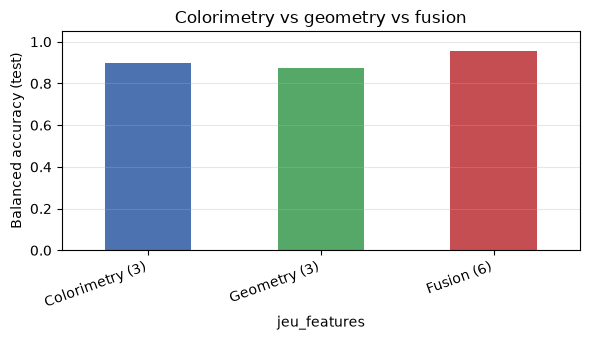


--- Fusion (6 features) ---
              precision    recall  f1-score   support

         pre       0.97      0.96      0.96        96
         per       0.93      0.98      0.96        98
        post       0.97      0.93      0.95        98

    accuracy                           0.96       292
   macro avg       0.96      0.96      0.96       292
weighted avg       0.96      0.96      0.96       292



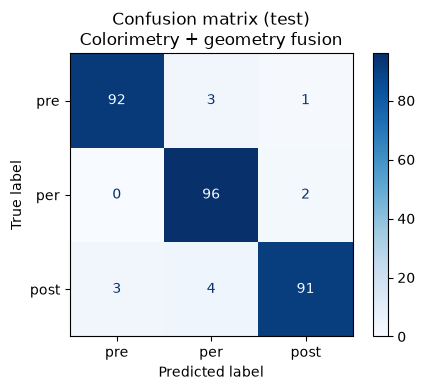

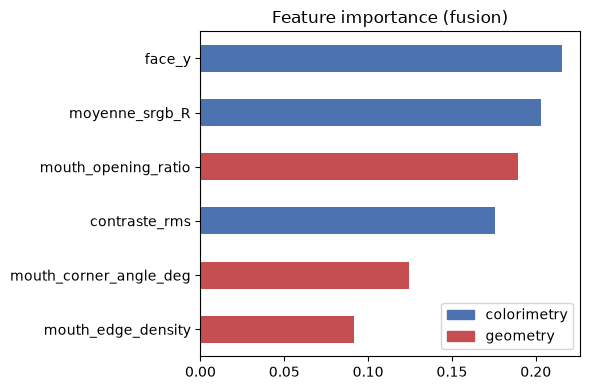

Importance share by method:
 colorimetry    0.594
geometry       0.406


In [74]:
# Final evaluation on the TEST set (only once)
lignes, preds = [], {}
for nom_jeu, feats in JEUX_FEATURES.items():
    pred = final_models[nom_jeu].predict(d_test[feats])
    preds[nom_jeu] = pred
    lignes.append({"jeu_features": nom_jeu, "n_features": len(feats),
                   "accuracy": accuracy_score(y_test, pred),
                   "balanced_accuracy": balanced_accuracy_score(y_test, pred)})
resume = pd.DataFrame(lignes).set_index("jeu_features").round(3)
print(resume)

fig, ax = plt.subplots(figsize=(6, 3.5))
resume["balanced_accuracy"].plot.bar(ax=ax, color=["#4C72B0", "#55A868", "#C44E52", "#8172B3"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Balanced accuracy (test)"); ax.grid(axis="y", alpha=.3)
ax.set_title("Colorimetry vs geometry vs fusion"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.savefig("figures/comparaison_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

# Detailed report + confusion matrix for the fusion model
print("\n--- Fusion (6 features) ---")
print(classification_report(y_test, preds["Fusion (6)"], labels=GROUPES, zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, preds["Fusion (6)"], labels=GROUPES, cmap="Blues", ax=ax)
ax.set_title("Confusion matrix (test)\nColorimetry + geometry fusion")
plt.tight_layout(); plt.savefig("figures/confusion_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

# Feature importance in the fused model
rf = final_models["Fusion (6)"]
imp = pd.Series(rf.feature_importances_, index=TOP_FUSION).sort_values()
couleurs = ["#4C72B0" if SOURCE[f] == "colorimetry" else "#C44E52" for f in imp.index]
fig, ax = plt.subplots(figsize=(6, 4))
imp.plot.barh(ax=ax, color=couleurs, title="Feature importance (fusion)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#C44E52")],
          labels=["colorimetry", "geometry"], loc="lower right")
plt.tight_layout(); plt.savefig("figures/importance_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

part = imp.groupby(imp.index.map(SOURCE)).sum().round(3)
print("Importance share by method:\n", part.to_string())

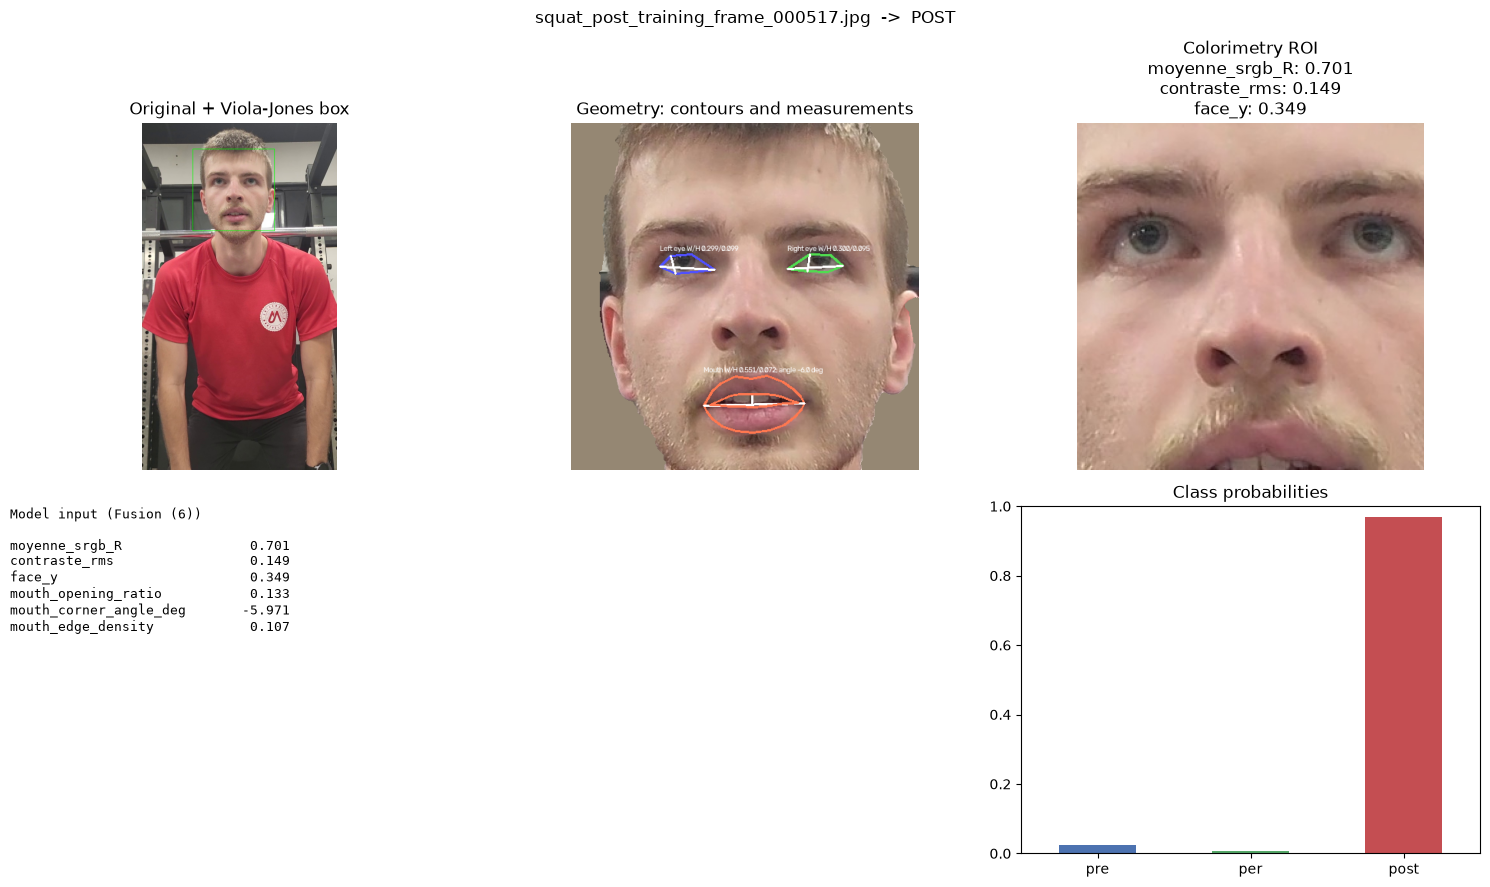

'post'

In [78]:
# --- Visualize what the model extracts (geometry + colorimetry) ---
_COLORS = {"oeil_g": (255, 80, 80), "oeil_d": (80, 220, 80), "bouche": (80, 120, 255)}
_MEASUREMENTS = {  # landmark pairs drawn for each region (width, height)
    "oeil_g": [(33, 133), (160, 144)],
    "oeil_d": [(362, 263), (385, 380)],
    "bouche_ext": [(61, 291), (13, 14)],
}


def _geometry_view(face, geometry):
    """Return the background-removed face with landmark contours and measurements."""
    view = face.copy()
    points = _points_landmarks(face)
    if points is None:
        return view

    labels = {
        "oeil_g": f"Left eye W/H {geometry['eye_left_width']:.3f}/{geometry['eye_left_height']:.3f}",
        "oeil_d": f"Right eye W/H {geometry['eye_right_width']:.3f}/{geometry['eye_right_height']:.3f}",
        "bouche_ext": (
            f"Mouth W/H {geometry['mouth_width']:.3f}/{geometry['mouth_height']:.3f}; "
            f"angle {geometry['mouth_corner_angle_deg']:.1f} deg"
        ),
    }

    for name, indices in _GROUPES_LANDMARKS.items():
        polygon = np.rint(points[np.asarray(indices, dtype=int)]).astype(np.int32).reshape(-1, 1, 2)
        color = _COLORS["bouche"] if name.startswith("bouche") else _COLORS.get(name, (255, 255, 255))
        cv2.polylines(view, [polygon], True, color, 2)
        for a, b in _MEASUREMENTS.get(name, []):
            cv2.line(view, tuple(np.rint(points[a]).astype(int)),
                     tuple(np.rint(points[b]).astype(int)), (255, 255, 255), 2)
        if name in labels:
            origin = np.rint(polygon.reshape(-1, 2).min(axis=0)).astype(int)
            cv2.putText(view, labels[name], (max(0, int(origin[0])), max(12, int(origin[1]) - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    return view


def test_image(chemin, jeu=None):
    """Classify an image and display the extracted geometry and color features."""
    jeu = jeu or "Fusion (6)"
    if jeu not in final_models:
        raise ValueError(f"Unknown feature set: {jeu}. Available sets: {list(final_models)}")

    feats = extract_features(chemin)
    if feats is None:
        print("Image unusable (no face or landmarks not found).")
        return None

    columns = JEUX_FEATURES[jeu]
    X = pd.DataFrame([feats])[columns]
    model = final_models[jeu]
    prediction = model.predict(X)[0]
    probabilities = pd.Series(model.predict_proba(X)[0], index=model.classes_).reindex(GROUPES)

    image = cv2.imread(str(chemin))
    if image is None:
        raise FileNotFoundError(f"Unable to read image: {chemin}")
    bbox = detect_face(image)
    if bbox is None:
        print("Image unusable (no face detected).")
        return None

    face = reframe(image, bbox, roi_ratio=1.0)
    face_without_background = remove_background(face)          # returns ONE image (no tuple)
    geometry, landmarks_ok = geometrie(face_without_background)
    if not landmarks_ok:
        print("Image unusable (face landmarks not found).")
        return None

    color_roi = reframe(image, bbox, ROI_RATIO)
    original_view = image.copy()
    x, y, w, h = bbox
    cv2.rectangle(original_view, (x, y), (x + w, y + h), (0, 255, 0), 2)
    geometry_view = _geometry_view(face_without_background, geometry)

    color_features = {column: feats[column] for column in TOP_COLOR if column in feats}
    color_title = "Colorimetry ROI\n" + "\n".join(
        f"{key}: {value:.3f}" for key, value in color_features.items()
    )

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes[0, 0].imshow(cv2.cvtColor(original_view, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title("Original + Viola-Jones box")
    axes[0, 1].imshow(cv2.cvtColor(geometry_view, cv2.COLOR_BGR2RGB))
    axes[0, 1].set_title("Geometry: contours and measurements")
    axes[0, 2].imshow(cv2.cvtColor(color_roi, cv2.COLOR_BGR2RGB))
    axes[0, 2].set_title(color_title)
    for axis in axes[0]:
        axis.axis("off")

    axes[1, 0].axis("off")
    feature_text = "\n".join(f"{column:<26}{feats[column]:>9.3f}" for column in columns)
    axes[1, 0].text(0.0, 1.0, f"Model input ({jeu})\n\n{feature_text}", va="top",
                    family="monospace", fontsize=9, transform=axes[1, 0].transAxes)

    axes[1, 1].axis("off")
    probabilities.plot.bar(ax=axes[1, 2], color=["#4C72B0", "#55A868", "#C44E52"])
    axes[1, 2].set_ylim(0, 1)
    axes[1, 2].tick_params(axis="x", rotation=0)
    axes[1, 2].set_title("Class probabilities")

    plt.suptitle(f"{Path(chemin).name}  ->  {prediction.upper()}")
    plt.tight_layout()
    plt.show()
    return prediction


test_image(chemin=Path("../dataset_computervision_LECSIN/dataset_squat/squat_post/squat_post_training_frame_000517.jpg"), jeu="Fusion (6)")